## Teste Z de duas amostras

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.stats import weightstats

In [2]:
df = pd.read_csv('Two_Machines.csv')

In [3]:
df

,Volume,Machine
0,154.27,Machine 1
1,150.03,Machine 1
2,151.14,Machine 1
3,145.47,Machine 1
4,149.71,Machine 1
...,...,...
195,152.05,Machine 2
196,151.41,Machine 2
197,153.76,Machine 2
198,150.75,Machine 2


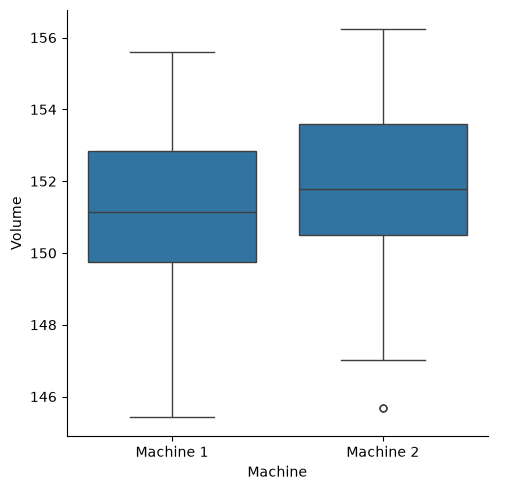

In [4]:
sns.catplot(data=df, x='Machine', y="Volume", kind='box')

In [7]:
m1= df[df['Machine']=='Machine 1']['Volume']
m2 = df[df['Machine']=='Machine 2']['Volume']

Vamos agora fazer o teste Z para as duas máquinas (Teste Z de duas amostras). \
Começamos filtrando os volumes da Máquina 1.

h0: u1 = u2 \
ha: u1 <> u2

In [8]:
weightstats.ztest(m1,m2)

(np.float64(-2.189406040190184), np.float64(0.028567341032618248))

Como P Value < 0.5, falhamos em rejeitamos a hipótese nula. Portanto, as máquinas estão produzindo com médias diferentes.

### Exercício 1 


A biblioteca Seaborn tem vários "built-in" datasets.

In [9]:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [18]:
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Primeiro é necessário verificar se há no mínimo 30 amostras para que seja possível realizar o teste Z.

Podemos obter maiores informações sobre o nosso dataset usando a função describe e plotando um gráfico.

Vamos plotar um boxplot para observar como as gorjetas estão distribuídas entre homens e mulheres.

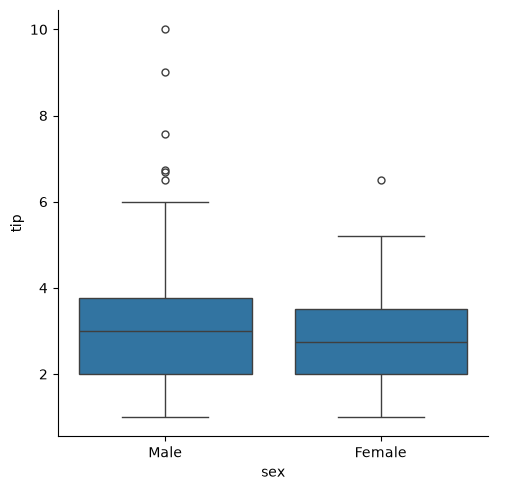

In [15]:
sns.catplot(data=tips, x='sex', y='tip', kind='box')

Para realizar nosso Teste Z, a primeira coisa a fazer é filtrar as gorjetas por sexo.

In [ ]:
tip_male = tips[tips['sex'] == 'Male']['tip']
tip_female = tips[tips['sex'] == 'Female']['tip']

In [23]:
weightstats.ztest(tip_male, tip_female)

(np.float64(1.3878597054212687), np.float64(0.1651797698624794))

Como P Value > 0,05, falhamos em rejeitar a hipótese nula, portanto as gorjetas de homens e mulheres são iguais.

### Exercício 2: Lunch vs Dinner

Realize um teste de hipótese que verifica se as gorjetas dadas no almoço são iguais às gorjetas dadas no jantar.

In [25]:
tip_din = tips[tips['time'] == 'Dinner']['tip']
tip_lunch = tips[tips['time'] == 'Lunch']['tip']

In [26]:
weightstats.ztest(tip_din, tip_lunch)

(np.float64(1.9062569301202392), np.float64(0.05661687925222567))

Como P Value > 0,05, falhamos em rejeitar a hipótese nula, portanto as gorjetas do almoço tem a mesma média que as gorjetas do jantar.

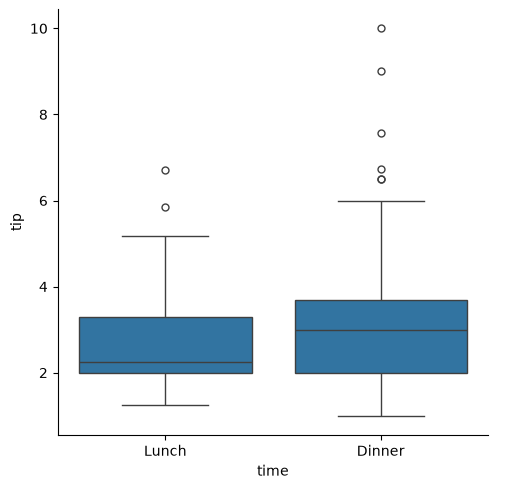

In [27]:
sns.catplot(data=tips, y='tip', x='time', kind='box')

## Teste t de duas amostras

Exemplo 1: Amostras envasadas por duas máquinas apresentam os seguintes volumes: \
Máquina A: 150, 152, 154, 152, 151 \
Máquina B: 156, 155, 158, 155, 154 \
A média é diferente? Calcular com 95% de confiança.

In [30]:
mA= [150, 152, 154, 152, 151]
mB = [156, 155, 158, 155, 154]

é a e b \

H0: μ1 = μ2 \
Ha: μ1 ≠ μ2

In [31]:
stats.ttest_ind(mA, mB, equal_var=True)

TtestResult(statistic=np.float64(-4.005551702879929), pvalue=np.float64(0.003919295477128334), df=np.float64(8.0))

Como P Value < 0,05, rejeitamos a hipótese nula. Portanto máquinas estão envazando com médias diferentes.

Exemplo 2: Amostras envasadas por duas máquinas têm apresentam os seguintes volumes: \
Máquina A: 150, 152, 154, 152, 151 \
Máquina C: 144, 162, 177, 150, 140 \
A média é diferente? Calcular com 95% de confiança.

In [32]:
mA= [150, 152, 154, 152, 151]
mC = [144, 162, 177, 150, 140]

In [34]:
stats.ttest_ind(mA, mC, equal_var=True)

TtestResult(statistic=np.float64(-0.4146442144313621), pvalue=np.float64(0.689298084249559), df=np.float64(8.0))

Como P Value > 0,05, falhamos em rejeitar a hipótese nula. Portanto, as máquinas estão produzindo com mesma média =>  μ(m1) = μ(m2).

## Exercício 3
Utilizando o dataset Titanic, realize um teste de hipótese que verifica se as médias das idades de homens e mulheres que sobreviveram à tragédia do Titanic são iguais. \
Importante: use df.dropna(subset = ['age'], inplace=True) para excluir os registros quem contém NaN na coluna 'age'.

In [37]:
df = sns.load_dataset('titanic')
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [38]:
df.dropna(subset = ['age'], inplace=True)

In [40]:
df = df[df['alive'] == 'yes']

In [42]:
tit_male = df[df['sex'] == 'male']['age']
tit_female = df[df['sex'] == 'female']['age']

In [47]:
weightstats.ztest(tit_male, tit_female)

# não, a idade é igual, 04 >0.05, falahmoa sem rejetiar a hip nula

(np.float64(-0.8351170125126802), np.float64(0.40365182882615236))